In [1]:
!nvidia-smi

Mon Nov 23 17:47:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    props = torch.cuda.get_device_properties(0)

    print(
        "VRAM:",
        round(props.total_memory / 1024**3, 2),
        "GB"
    )

CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB


In [3]:
%pip install "transformers[torch,vision,audio] @ git+https://github.com/swiss-ai/transformers.git@apertusv1p5-release-pre-upstream"

  Cloning https://github.com/swiss-ai/transformers.git (to revision apertusv1p5-release-pre-upstream) to /tmp/pip-install-hqx_vwzi/transformers_15b4bd5c17574708ab9b32dada14a66b
  Running command git clone --filter=blob:none --quiet https://github.com/swiss-ai/transformers.git /tmp/pip-install-hqx_vwzi/transformers_15b4bd5c17574708ab9b32dada14a66b
  Running command git checkout -q 3797303dda74844e3d1f8977ff5518bb91f818b4
  Resolved https://github.com/swiss-ai/transformers.git to commit 3797303dda74844e3d1f8977ff5518bb91f818b4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 91.4 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 117.9 MB/s  0:00:00
   

In [26]:
from huggingface_hub import login
from google.colab import userdata

login(token=userdata.get("HF_TOKEN"))

In [29]:
!unzip -q -o seminar_labs.zip
%cd seminar_labs

unzip:  cannot find or open seminar_labs.zip, seminar_labs.zip.zip or seminar_labs.zip.ZIP.
[Errno 2] No such file or directory: 'seminar_labs'
/content/drive/MyDrive/Crosslingual-Behavioral-Testing-of-Semantic-Robustness-in-NLP-Models/seminar_labs


In [30]:
import seminar_toolkit as toolkit

In [31]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
%cd /content/drive/MyDrive/Crosslingual-Behavioral-Testing-of-Semantic-Robustness-in-NLP-Models

/content/drive/MyDrive/Crosslingual-Behavioral-Testing-of-Semantic-Robustness-in-NLP-Models


In [33]:
import sys
from pathlib import Path
from huggingface_hub import model_info

# Ensure seminar_toolkit/ is importable
# PROJECT_DIR = Path.cwd()
# print("Current working directory:", PROJECT_DIR)
# print("Contents:", [p.name for p in PROJECT_DIR.iterdir()])


# 1. Global deterministic seed (GUIDE.md Section 3 & Section 7)
SEED = 0
toolkit.set_seed(SEED)

# 2. Centralized # EDIT: configuration (GUIDE.md Section 1 & Section 7 Checklist)
MODEL_ID = "swiss-ai/Apertus-v1.5-8B"
DATASET = "trial_suite_master.csv"
LANGUAGE = "en"
EVAL_MODE = "zeroshot"

# 3. Record exact Hugging Face commit SHA (GUIDE.md Section 5.6 & Section 7)
MODEL_REVISION = model_info(MODEL_ID).sha
print(f"Model: {MODEL_ID} | Revision SHA: {MODEL_REVISION}")

Model: swiss-ai/Apertus-v1.5-8B | Revision SHA: 1519de0ae7f3d114879291810a58259966f64c99


# Load Model

In [34]:
from transformers import (
    AutoModelForMultimodalLM,
    AutoProcessor
)

MODEL_ID = "swiss-ai/Apertus-v1.5-8B"

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = AutoModelForMultimodalLM.from_pretrained(
    MODEL_ID,
    dtype="auto",
    device_map="auto"
).eval()

RESOLVED_DTYPE = str(next(model.parameters()).dtype)
RESOLVED_DEVICE = str(next(model.parameters()).device)
print(f"Apertus loaded successfully! dtype={RESOLVED_DTYPE}, device={RESOLVED_DEVICE}")

processor_config.json:   0%|          | 0.00/763 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/16.6k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.61k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.03k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 44.0MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (4 outputs left out)

[transformers] CUDA-fused xIELU not available (No module named 'xielu') – falling back to a Python version.
For CUDA xIELU (experimental), `pip install git+https://github.com/nickjbrowning/XIELU`


Loading weights:   0%|          | 0/924 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/157 [00:00<?, ?B/s]

Apertus loaded successfully! dtype=torch.bfloat16, device=cuda:0


# Zero-shot Prompting

In [35]:
SYSTEM_PROMPT = """
You are an expert Natural Language Inference (NLI) classifier.

Determine the logical relationship between a premise
and a hypothesis.

There are exactly three possible labels:

- Entailment: If the premise is true, the hypothesis
  must also be true.
- Contradiction: The premise and hypothesis cannot
  both be true.
- Neutral: The premise neither entails nor contradicts
  the hypothesis.

Base your decision only on the provided information.
Do not introduce unsupported assumptions.

Respond with exactly ONE lowercase label:
entailment, neutral, or contradiction.

Do not provide explanations or additional text.
"""


def predict_nli(premise, hypothesis):

    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": (
                f"Premise: {premise}\n"
                f"Hypothesis: {hypothesis}\n"
                "NLI label:"
            )
        }
    ]

    # Format the conversation using Apertus's chat template
    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(model.device)

    # Generate the answer
    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False
        )

    # Decode only the newly generated tokens
    generated_ids = output_ids[
        0,
        inputs["input_ids"].shape[-1]:
    ]

    response = processor.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    return response

In [36]:
import torch
# Test examples before processing the dataset
test_examples = [
    {
        "premise": "The student did not pass the examination.",
        "hypothesis": "The student passed the examination.",
        "gold": "contradiction"
    },
    {
        "premise": "All three students passed the examination.",
        "hypothesis": "At least one of the three students passed.",
        "gold": "entailment"
    },
    {
        "premise": "Some students passed the examination.",
        "hypothesis": "All students passed the examination.",
        "gold": "neutral"
    }
]

for example in test_examples:

    prediction = predict_nli(
        example["premise"],
        example["hypothesis"]
    )

    print("Premise:", example["premise"])
    print("Hypothesis:", example["hypothesis"])
    print("Gold:", example["gold"])
    print("Prediction:", prediction)
    print("-" * 50)

Premise: The student did not pass the examination.
Hypothesis: The student passed the examination.
Gold: contradiction
Prediction: contradiction
--------------------------------------------------
Premise: All three students passed the examination.
Hypothesis: At least one of the three students passed.
Gold: entailment
Prediction: entailment
--------------------------------------------------
Premise: Some students passed the examination.
Hypothesis: All students passed the examination.
Gold: neutral
Prediction: contradiction
--------------------------------------------------


#

In [37]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Crosslingual-Behavioral-Testing-of-Semantic-Robustness-in-NLP-Models/trial_suite_master.csv")

print(df.head())
print("Total examples:", len(df))

         case_id        test_id language phenomenon               subcategory  \
0  en_neg_mft_01  en_neg_mft_01       en   negation  frequency_negation_never   
1  en_neg_mft_02  en_neg_mft_02       en   negation        predicate_negation   
2  en_neg_mft_03  en_neg_mft_03       en   negation      negation_via_without   
3  en_neg_mft_04  en_neg_mft_04       en   negation  negative_pronoun_nothing   
4  en_neg_mft_05  en_neg_mft_05       en   negation   negation_in_conditional   

  test_type pair_role                                            premise  \
0       MFT    single       Marta has never visited the northern office.   
1       MFT    single     The delivery driver did not ring the doorbell.   
2       MFT    single                 Ravi left the shop without paying.   
3       MFT    single            Nothing in the drawer belongs to Oscar.   
4       MFT    single  If the printer is out of paper, it does not pr...   

                                     hypothesis     gold

In [38]:
df = df[
    df["review_status"].astype(str).str.lower() == "accept"
].copy()

df = df[df["language"] == "en"].copy()

In [39]:
predictions = []

for index, row in df.iterrows():

    prediction = predict_nli(
        row["premise"],
        row["hypothesis"]
    )

    predictions.append(prediction)

    if len(predictions) % 10 == 0:
        print(f"Processed {len(predictions)}/{len(df)}")

Processed 10/48
Processed 20/48
Processed 30/48
Processed 40/48


In [40]:
df["apertus_raw_prediction"] = predictions

In [41]:
# Parse Labels & Add Toolkit Columns
import re
import numpy as np
import pandas as pd

VALID_LABELS = {"entailment", "neutral", "contradiction"}

def parse_label(response):
    lines = str(response).strip().splitlines()
    if not lines:
        return "invalid"
    cleaned = lines[0].strip().lower().strip(" *`#.:,\"'")
    match = re.fullmatch(r"(?:label\s*:\s*)?(entailment|neutral|contradiction)", cleaned)
    return match.group(1) if match else "invalid"

df["gold_label"] = df["gold_label"].astype(str).str.strip().str.lower()
df["prediction"] = df["apertus_raw_prediction"].apply(parse_label)
df["correct"] = df["prediction"] == df["gold_label"]
# Required by toolkit.accuracy and toolkit.accuracy_by (GUIDE.md Section 2.1 & 2.5)
df["prefers_correct"] = df["correct"].astype(int)

n_invalid = int((df["prediction"] == "invalid").sum())
print(f"Total evaluated rows: {len(df)} | Invalid outputs: {n_invalid}")

Total evaluated rows: 48 | Invalid outputs: 0


# Evaluation

In [42]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

valid = df[df["prediction"] != "invalid"].copy()

print(
    "Accuracy:",
    accuracy_score(
        valid["gold_label"],
        valid["prediction"]
    )
)

print(
    "Macro F1:",
    f1_score(
        valid["gold_label"],
        valid["prediction"],
        labels=[
            "entailment",
            "neutral",
            "contradiction"
        ],
        average="macro"
    )
)

print(
    classification_report(
        valid["gold_label"],
        valid["prediction"],
        labels=[
            "entailment",
            "neutral",
            "contradiction"
        ]
    )
)

Accuracy: 0.875
Macro F1: 0.8634721678199938
               precision    recall  f1-score   support

   entailment       0.85      1.00      0.92        17
      neutral       1.00      0.64      0.78        14
contradiction       0.84      0.94      0.89        17

     accuracy                           0.88        48
    macro avg       0.90      0.86      0.86        48
 weighted avg       0.89      0.88      0.87        48



In [43]:
# Toolkit Metrics, Bootstrap CIs & Pairwise CheckList Audit
from sklearn.metrics import accuracy_score, f1_score, classification_report

# 1. Overall accuracy + 95% bootstrap confidence interval (GUIDE.md Section 2.5)
overall_acc = toolkit.accuracy(df)
ci_low, ci_high = toolkit.bootstrap_confidence_interval(
    df, bootstrap_samples=2000, confidence=95, seed=SEED
)

valid = df[df["prediction"] != "invalid"].copy()
macro_f1 = f1_score(
    valid["gold_label"],
    valid["prediction"],
    labels=["entailment", "neutral", "contradiction"],
    average="macro",
)

print(
    f"Overall Accuracy (all n={len(df)}): {overall_acc:.4f} "
    f"(95% Bootstrap CI: [{ci_low:.4f}, {ci_high:.4f}])"
)
print(f"Macro F1 (valid n={len(valid)}): {macro_f1:.4f}\n")
print(
    classification_report(
        valid["gold_label"],
        valid["prediction"],
        labels=["entailment", "neutral", "contradiction"],
        digits=4,
    )
)

# 2. Per-phenomenon and per-test_type summaries with 95% CIs (GUIDE.md Section 2.5)
by_phenomenon = toolkit.accuracy_by(df, by="phenomenon")
by_test_type = toolkit.accuracy_by(df, by="test_type")
print("\nAccuracy by Phenomenon:")
print(by_phenomenon)
print("\nAccuracy by Test Type:")
print(by_test_type)

# 3. Pairwise CheckList Behavioral Evaluation for INV and DIR (GUIDE.md Section 2.6)
orig = df[df["pair_role"] == "original"].set_index("test_id")
var = df[df["pair_role"] == "variation"].set_index("test_id")

pair_rows = []
for tid in orig.index.intersection(var.index):
    o, v = orig.loc[tid], var.loc[tid]
    orig_ok = int(o["prefers_correct"])
    var_ok = int(v["prefers_correct"])
    pair_rows.append({
        "test_id": tid,
        "phenomenon": o["phenomenon"],
        "subcategory": o["subcategory"],
        "test_type": o["test_type"],
        "gold_orig": o["gold_label"],
        "gold_var": v["gold_label"],
        "pred_orig": o["prediction"],
        "pred_var": v["prediction"],
        "original_holds": orig_ok,
        "robustness_holds": var_ok,
        "broke": int(orig_ok == 1 and var_ok == 0),
        "fixed": int(orig_ok == 0 and var_ok == 1),
        "flipped": int(o["prediction"] != v["prediction"]),
    })

pair_df = pd.DataFrame(pair_rows)
pair_summary = (
    pair_df.groupby("test_type")
    .agg(
        n_pairs=("test_id", "count"),
        original=("original_holds", "mean"),
        robustness=("robustness_holds", "mean"),
        broke=("broke", "mean"),
        fixed=("fixed", "mean"),
        flipped=("flipped", "mean"),
    )
    .round(3)
    .reset_index()
)
print("\nPairwise CheckList Summary (INV vs. DIR):")
print(pair_summary)

Overall Accuracy (all n=48): 0.8750 (95% Bootstrap CI: [0.7708, 0.9583])
Macro F1 (valid n=48): 0.8635

               precision    recall  f1-score   support

   entailment     0.8500    1.0000    0.9189        17
      neutral     1.0000    0.6429    0.7826        14
contradiction     0.8421    0.9412    0.8889        17

     accuracy                         0.8750        48
    macro avg     0.8974    0.8613    0.8635        48
 weighted avg     0.8910    0.8750    0.8685        48


Accuracy by Phenomenon:
      phenomenon  accuracy   n  ci_low  ci_high
0       negation    1.0000  14  0.7847   1.0000
1     quantifier    0.8824  17  0.7059   1.0000
2  semantic_role    0.7647  17  0.5882   0.9412

Accuracy by Test Type:
  test_type  accuracy   n  ci_low  ci_high
0       MFT    0.9286  14  0.7857      1.0
1       DIR    0.8750  16  0.6875      1.0
2       INV    0.8333  18  0.6667      1.0

Pairwise CheckList Summary (INV vs. DIR):
  test_type  n_pairs  original  robustness  broke  f

In [44]:
# Save All Tables & Metadata via seminar_toolkit (GUIDE.md Sections 6.1 & 7)
base_metadata = {
    "day": 1,
    "evaluation_mode": EVAL_MODE,
    "model": MODEL_ID,
    "revision": MODEL_REVISION,
    "dtype": RESOLVED_DTYPE,
    "device": RESOLVED_DEVICE,
    "dataset": DATASET,
    "language": LANGUAGE,
    "filter": "review_status == 'Accept'",
    "n_evaluated": int(len(df)),
    "n_invalid": n_invalid,
    "seed": SEED,
    "bootstrap_samples": 2000,
    "overall_accuracy": round(float(overall_acc), 4),
    "ci_low": round(float(ci_low), 4),
    "ci_high": round(float(ci_high), 4),
    "macro_f1": round(float(macro_f1), 4),
    "environment": toolkit.environment_report(),
}

# 1. Save row-level predictions -> results/day1_zeroshot_swiss-ai_Apertus-v1_5-8B_trial_suite_master_en.*
pred_name = toolkit.result_name("day1_zeroshot", MODEL_ID, DATASET, LANGUAGE)
toolkit.save_results(df, pred_name, metadata=base_metadata)

# 2. Save per-phenomenon and per-test-type summary tables
toolkit.save_results(
    by_phenomenon,
    toolkit.result_name("day1_zeroshot_by_phenomenon", MODEL_ID, DATASET, LANGUAGE),
    metadata=base_metadata,
)
toolkit.save_results(
    by_test_type,
    toolkit.result_name("day1_zeroshot_by_test_type", MODEL_ID, DATASET, LANGUAGE),
    metadata=base_metadata,
)

# 3. Save pairwise INV/DIR behavioral tables (GUIDE.md Section 2.6)
toolkit.save_results(
    pair_df,
    toolkit.result_name("day3_zeroshot_pairs", MODEL_ID, DATASET, LANGUAGE),
    metadata=base_metadata,
)
toolkit.save_results(
    pair_summary,
    toolkit.result_name("day3_zeroshot_pair_summary", MODEL_ID, DATASET, LANGUAGE),
    metadata=base_metadata,
)

print("Saved all CSV and .meta.json files to results/:")
print(toolkit.list_results())

Saved all CSV and .meta.json files to results/:
['day1_zeroshot_by_phenomenon_swiss-ai_Apertus-v1_5-8B_trial_suite_master_en', 'day1_zeroshot_by_test_type_swiss-ai_Apertus-v1_5-8B_trial_suite_master_en', 'day1_zeroshot_swiss-ai_Apertus-v1_5-8B_trial_suite_master_en', 'day3_zeroshot_pair_summary_swiss-ai_Apertus-v1_5-8B_trial_suite_master_en', 'day3_zeroshot_pairs_swiss-ai_Apertus-v1_5-8B_trial_suite_master_en']


['case_id', 'test_id', 'language', 'phenomenon', 'subcategory', 'test_type', 'pair_role', 'premise', 'hypothesis', 'gold_label', 'review_status', 'apertus_raw_prediction', 'prediction', 'correct']
              case_id        test_id language phenomenon  \
0       en_neg_mft_01  en_neg_mft_01       en   negation   
1       en_neg_mft_02  en_neg_mft_02       en   negation   
2       en_neg_mft_03  en_neg_mft_03       en   negation   
3       en_neg_mft_04  en_neg_mft_04       en   negation   
4  en_neg_inv_01_orig  en_neg_inv_01       en   negation   

                      subcategory test_type pair_role  \
0        frequency_negation_never       MFT    single   
1              predicate_negation       MFT    single   
2            negation_via_without       MFT    single   
3        negative_pronoun_nothing       MFT    single   
4  npi_any_vs_negative_determiner       INV  original   

                                             premise  \
0       Marta has never visited the norther

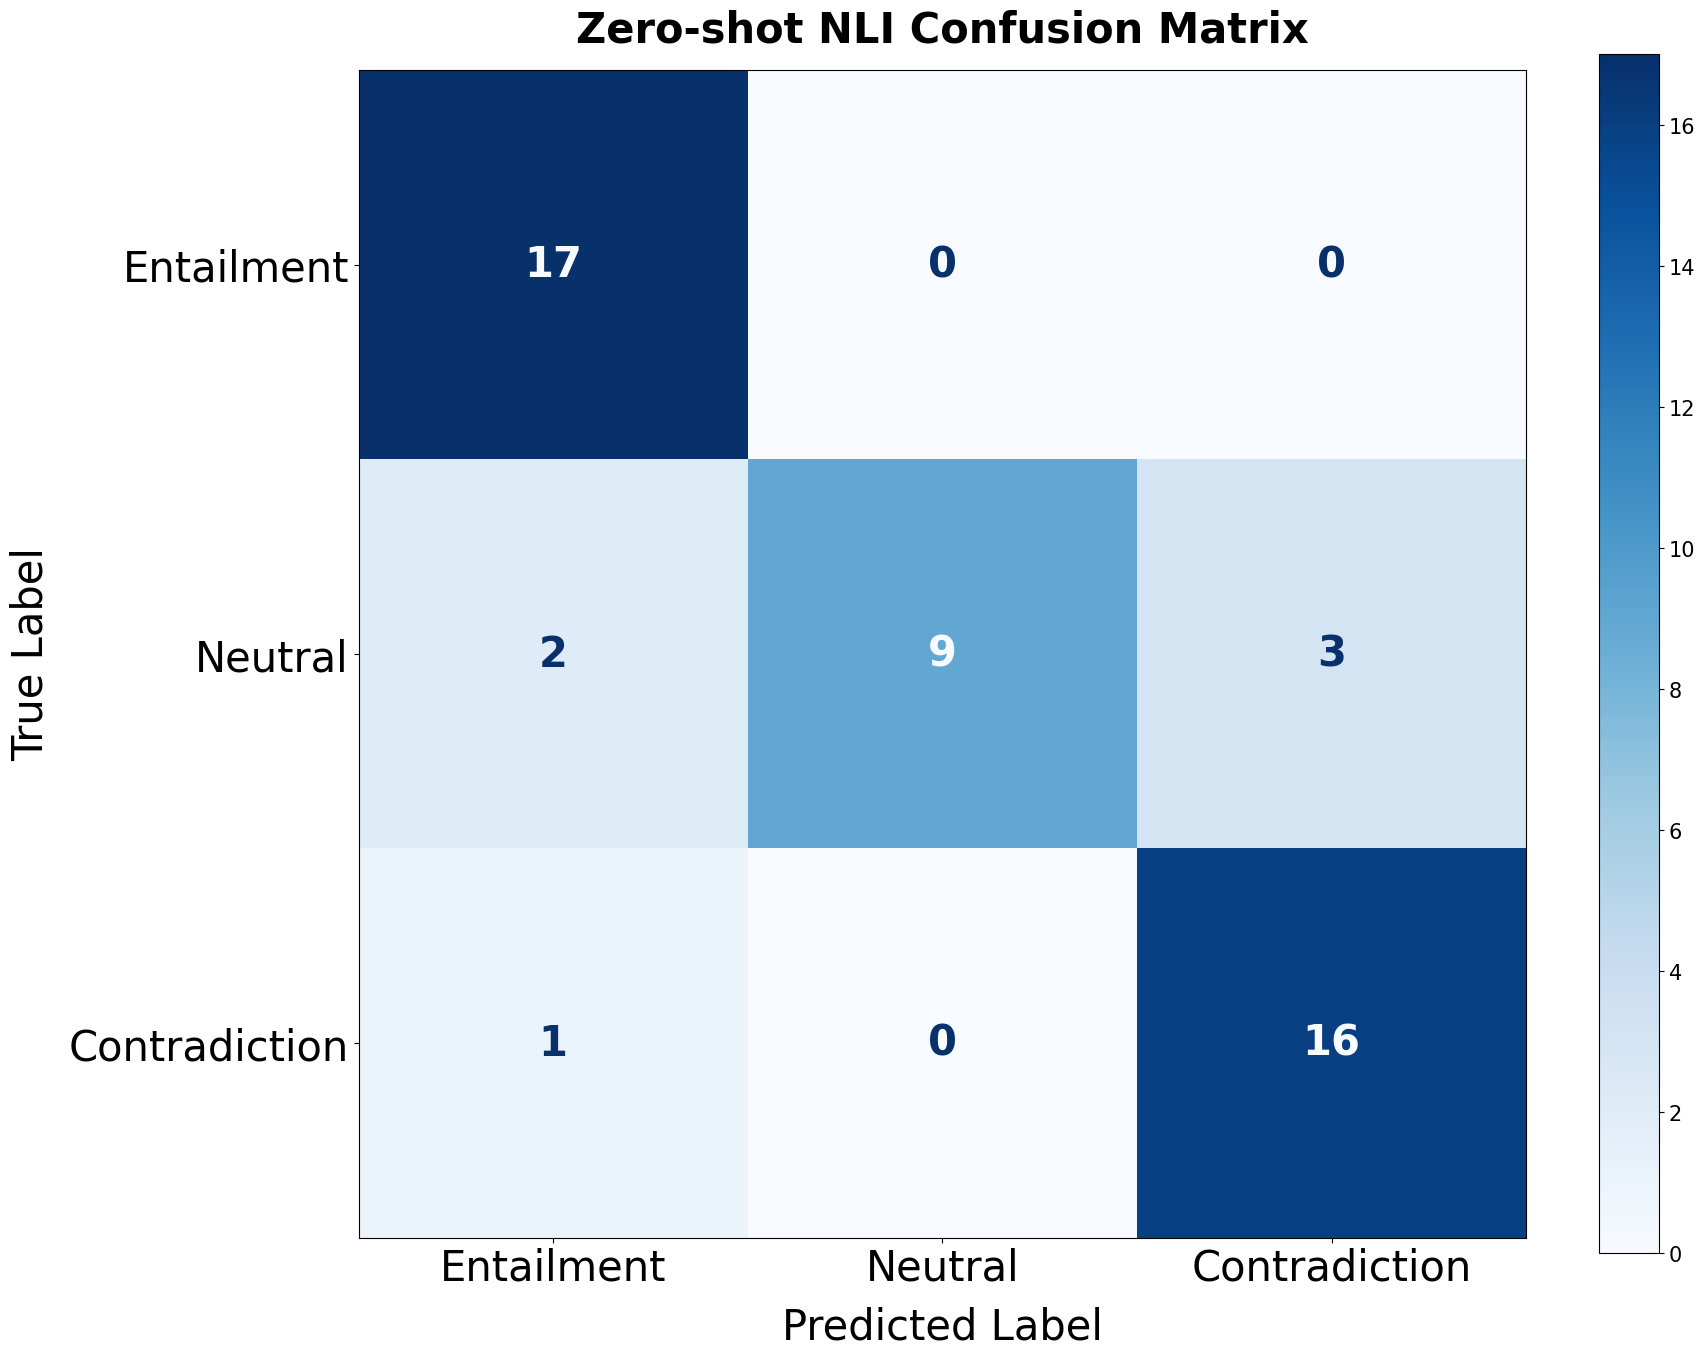

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load previously saved predictions
valid = pd.read_csv("apertus_trial_suite_predictions_2.csv")

# Check that the required columns exist
print(valid.columns.tolist())
print(valid.head())

# Define the class labels in a fixed order
labels = ["entailment", "neutral", "contradiction"]
display_labels = ["Entailment", "Neutral", "Contradiction"]

# Clean the labels
y_true = valid["gold_label"].astype("string").str.strip().str.lower()
y_pred = valid["prediction"].astype("string").str.strip().str.lower()

# Check for missing or unexpected labels
assert y_true.notna().all(), "Missing gold labels detected"
assert y_pred.notna().all(), "Missing predictions detected"

assert set(y_true.unique()).issubset(labels), "Unexpected gold labels"
assert set(y_pred.unique()).issubset(labels), "Unexpected predicted labels"

# Calculate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

# Create a larger figure
fig, ax = plt.subplots(figsize=(18, 14))

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

# Title and axis labels
ax.set_title(
    "Zero-shot NLI Confusion Matrix",
    fontsize=30,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Predicted Label", fontsize=30, labelpad=12)
ax.set_ylabel("True Label", fontsize=30, labelpad=12)

# Improve tick labels
ax.tick_params(axis="both", labelsize=30)

# Improve cell annotation sizes
for text in disp.text_.ravel():
    text.set_fontsize(30)
    text.set_fontweight("bold")

# Improve colorbar
disp.im_.colorbar.ax.tick_params(labelsize=15)

# Adjust spacing
fig.tight_layout()

# Save high-resolution PNG
fig.savefig(
    "trial_confusion_matrix.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)

# Also save as PDF for poster use
fig.savefig(
    "trial_confusion_matrix.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)